# Grid search backtest

Tries every combination in each model's grid: naive, gradient boosting, Greykite, and Chronos-2. Every config is backtested on the same rolling as-of dates and scored on MAE, RMSE, MAPE, WAPE, and bias.

## Setup

All imports live here. The notebook moves to the repo root so it uses the same config and MLflow store as `natgas tune`.

In [1]:
import logging
import os
import warnings
from pathlib import Path

os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"
os.environ["HF_HUB_DISABLE_TELEMETRY"] = "1"
os.environ["TRANSFORMERS_NO_ADVISORY_WARNINGS"] = "1"
os.environ["HF_HUB_DISABLE_EXPERIMENTAL_WARNING"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import matplotlib.pyplot as plt
import mlflow
import pandas as pd

from natgas.config import load_settings
from natgas.forecasting.backtesting import Backtester
from natgas.forecasting.data import ForecastDataProvider
from natgas.forecasting.models.chronos.ChronosModel import ChronosModel
from natgas.forecasting.models.chronos.ChronosModelConfig import ChronosModelConfig
from natgas.forecasting.optimization import GridSearchOptimizer
from natgas.forecasting.tuning import ModelPublisher, TuningConfig

# Run from the repo root so config files, mlflow.db, and mlruns/ line up
if Path.cwd().name == "experiments":
    os.chdir(Path.cwd().parent)

warnings.filterwarnings("ignore")
logging.getLogger().setLevel(logging.WARNING)
for name in ["natgas", "mlflow", "greykite", "optuna", "huggingface_hub", "transformers", "torch"]:
    logging.getLogger(name).setLevel(logging.ERROR)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

# Download Chronos-2 once, then stay offline so worker processes do not
# retry Hugging Face and print timeout warnings.
ChronosModel.pipeline_for(ChronosModelConfig().model_id, "cpu")
os.environ["HF_HUB_OFFLINE"] = "1"

# Greykite switches matplotlib to a file backend, so turn inline charts back on
%matplotlib inline

## Data

`ForecastDataProvider` is the only way models get data. Every as-of date gets training data up to that date and the next 5 trading days to score against. The dates are the same in both notebooks, so the results are comparable.

In [2]:
tuning = TuningConfig.from_yaml("config/tuning.yaml")
settings = load_settings()
provider = ForecastDataProvider.from_settings(settings, tuning.horizon_days, tuning.target_column)
as_of_dates = provider.backtest_dates(tuning.backtest_start, tuning.backtest_end, tuning.step_days)

first, last = provider.first_date.date(), provider.last_date.date()
print(f"prices: {first} to {last}, {len(provider.target)} trading days")
print(f"features: {provider.feature_columns}")
print(
    f"{len(as_of_dates)} as-of dates from {as_of_dates[0].date()} to {as_of_dates[-1].date()}, "
    f"{tuning.horizon_days} trading days ahead each"
)

prices: 2015-01-02 to 2026-11-18, 2989 trading days
features: ['hdd', 'cdd', 'christmas_day', 'christmas_day_pre_1', 'christmas_day_pre_2', 'christmas_day_pre_3', 'christmas_day_pre_4', 'christmas_day_post_1', 'christmas_day_post_2', 'christmas_day_post_3', 'christmas_day_post_4', 'columbus_day', 'columbus_day_pre_1', 'columbus_day_pre_2', 'columbus_day_pre_3', 'columbus_day_pre_4', 'columbus_day_post_1', 'columbus_day_post_2', 'columbus_day_post_3', 'columbus_day_post_4', 'independence_day', 'independence_day_pre_1', 'independence_day_pre_2', 'independence_day_pre_3', 'independence_day_pre_4', 'independence_day_post_1', 'independence_day_post_2', 'independence_day_post_3', 'independence_day_post_4', 'juneteenth_national_independence_day', 'juneteenth_national_independence_day_pre_1', 'juneteenth_national_independence_day_pre_2', 'juneteenth_national_independence_day_pre_3', 'juneteenth_national_independence_day_pre_4', 'juneteenth_national_independence_day_post_1', 'juneteenth_nationa

## Search space

Each model's options come from `config/tuning.yaml` (the `grid` key) and map into that model's config class.

In [3]:
spaces = {name: settings.get("grid") for name, settings in tuning.model_settings.items()}
pd.Series(spaces, name="grid").to_frame()

,grid
naive,None
gradient_boosting,"{'n_lags': [5, 10], 'learning_rate': [0.03, 0.1], 'max_depth': [2, 4], 'use_weather': [True, False]}"
greykite,"{'history_years': [2.0, 4.0], 'autoregression_lags': [0, 3], 'use_holidays': [True, False], 'holiday_window': [2, 4]}"
chronos,"{'context_length': [128, 512, 2048]}"


## Run the backtests

Each config is backtested on every as-of date and logged as a nested MLflow run.

In [4]:
backtester = Backtester(provider, as_of_dates, n_jobs=tuning.n_jobs)
optimizer = GridSearchOptimizer(backtester, tuning.selection_metric)

mlflow.set_tracking_uri(tuning.tracking_uri)
mlflow.set_experiment("natgas-grid-search")
with mlflow.start_run(run_name="grid-search-notebook") as search_run:
    mlflow.set_tag("method", "grid")
    mlflow.log_params({"backtest_count": len(as_of_dates), "horizon_days": tuning.horizon_days})
    summary = optimizer.run(tuning.model_settings)

print(f"{len(summary)} configs backtested, {len(optimizer.failed)} failed")

36 configs backtested, 0 failed


## Results

Lower is better. `skill_vs_naive` above zero means the config beats repeating the last price.

In [5]:
scores = ["mae", "rmse", "mape", "wape", "bias", "skill_vs_naive"]
columns = ["model_name", "config", *scores, "seconds"]
summary[columns].round(4)

,model_name,config,mae,rmse,mape,wape,bias,skill_vs_naive,seconds
0,gradient_boosting,"{""l2_regularization"": 0.0, ""learning_rate"": 0.03, ""max_depth"": 2, ""max_iter"": 200, ""min_samples_leaf"": 20, ""n_lags"":...",0.2462,0.3885,6.1917,6.4851,-0.0011,0.0000,1.5
1,naive,{},0.2462,0.3828,6.1637,6.4854,0.0001,0.0000,6.0
2,gradient_boosting,"{""l2_regularization"": 0.0, ""learning_rate"": 0.03, ""max_depth"": 2, ""max_iter"": 200, ""min_samples_leaf"": 20, ""n_lags"":...",0.2465,0.3894,6.2232,6.4941,0.0012,-0.0013,1.6
3,gradient_boosting,"{""l2_regularization"": 0.0, ""learning_rate"": 0.03, ""max_depth"": 4, ""max_iter"": 200, ""min_samples_leaf"": 20, ""n_lags"":...",0.2473,0.3932,6.2589,6.5138,0.0036,-0.0044,2.9
4,gradient_boosting,"{""l2_regularization"": 0.0, ""learning_rate"": 0.1, ""max_depth"": 2, ""max_iter"": 200, ""min_samples_leaf"": 20, ""n_lags"": ...",0.2479,0.3954,6.2827,6.5290,0.0075,-0.0067,1.6
5,chronos,"{""context_length"": 512, ""device"": ""cpu"", ""model_id"": ""amazon/chronos-2""}",0.2482,0.3874,6.1764,6.5386,-0.0098,-0.0082,3.0
6,gradient_boosting,"{""l2_regularization"": 0.0, ""learning_rate"": 0.03, ""max_depth"": 4, ""max_iter"": 200, ""min_samples_leaf"": 20, ""n_lags"":...",0.2485,0.3940,6.3017,6.5458,0.0018,-0.0093,2.7
7,gradient_boosting,"{""l2_regularization"": 0.0, ""learning_rate"": 0.1, ""max_depth"": 2, ""max_iter"": 200, ""min_samples_leaf"": 20, ""n_lags"": ...",0.2492,0.4021,6.2521,6.5627,0.0071,-0.0119,2.1
8,gradient_boosting,"{""l2_regularization"": 0.0, ""learning_rate"": 0.03, ""max_depth"": 2, ""max_iter"": 200, ""min_samples_leaf"": 20, ""n_lags"":...",0.2492,0.3876,6.2566,6.5642,-0.0077,-0.0121,2.3
9,gradient_boosting,"{""l2_regularization"": 0.0, ""learning_rate"": 0.03, ""max_depth"": 4, ""max_iter"": 200, ""min_samples_leaf"": 20, ""n_lags"":...",0.2498,0.3924,6.3148,6.5789,-0.0087,-0.0144,2.3


## Best config per model

In [6]:
best = optimizer.best_by_model()
best_table = pd.DataFrame(
    {name: {**report.metrics(), "config": report.config.to_json()} for name, report in best.items()}
).T.sort_values("mae")
best_table

,mae,rmse,mape,wape,bias,config
gradient_boosting,0.246208,0.388454,6.191729,6.485143,-0.001137,"{""l2_regularization"": 0.0, ""learning_rate"": 0.03, ""max_depth"": 2, ""max_iter"": 200, ""min_samples_leaf"": 20, ""n_lags"":..."
naive,0.246219,0.382759,6.163686,6.485441,0.000065,{}
chronos,0.248237,0.387382,6.176419,6.538598,-0.009802,"{""context_length"": 512, ""device"": ""cpu"", ""model_id"": ""amazon/chronos-2""}"
greykite,0.303544,0.450404,7.889966,7.995395,0.014585,"{""auto_changepoints"": false, ""autoregression_lags"": 3, ""fit_algorithm"": ""linear"", ""history_years"": 4.0, ""holiday_win..."


## Error by model and by days ahead

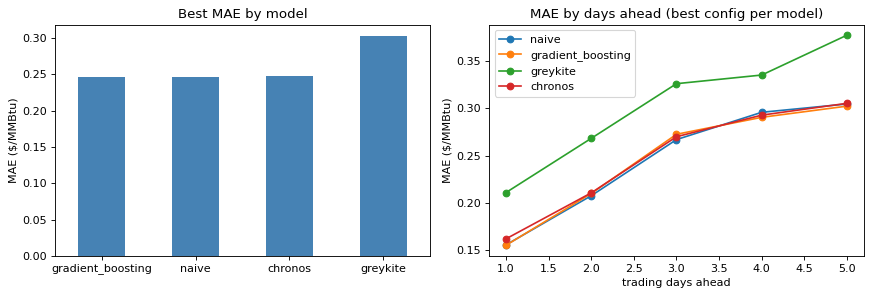

In [7]:
by_step = pd.DataFrame({name: report.metrics_by_step()["mae"] for name, report in best.items()})

figure, (left, right) = plt.subplots(1, 2, figsize=(11, 3.8), dpi=80)
best_table["mae"].astype(float).plot.bar(ax=left, color="steelblue")
left.set_title("Best MAE by model")
left.set_ylabel("MAE ($/MMBtu)")
left.tick_params(axis="x", rotation=0)
by_step.plot(ax=right, marker="o")
right.set_title("MAE by days ahead (best config per model)")
right.set_xlabel("trading days ahead")
right.set_ylabel("MAE ($/MMBtu)")
figure.tight_layout()
plt.show()

## Best config

The publishing rule only picks a model over naive when it lowers error by at least the margin in `tuning.yaml`.

In [8]:
publisher = ModelPublisher(
    provider,
    tuning.registered_model_name,
    tuning.model_alias,
    tuning.selection_metric,
    tuning.min_improvement,
)
decision = publisher.choose(optimizer.reports)
print(decision.reason)
print("model to publish:", decision.report.model_name, decision.report.config.to_json())

best was gradient_boosting at 0.00% better than naive, below the 1.00% margin, so naive is kept
model to publish: naive {}


## Publish

Retrain the chosen config on all data and register it in the MLflow model registry.

In [9]:
with mlflow.start_run(run_name=f"publish-{decision.report.model_name}"):
    mlflow.set_tags({"search_run_id": search_run.info.run_id, "method": "grid"})
    version = publisher.publish(decision)
print(f"registered {tuning.registered_model_name} version {version} as @{tuning.model_alias}")

registered natgas-price-forecaster version 5 as @champion


Registered model 'natgas-price-forecaster' already exists. Creating a new version of this model...
Created version '5' of model 'natgas-price-forecaster'.
